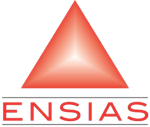

# TP 7 — Clustering Hiérarchique Ascendant (CAH)

**Module :** Introduction au Machine Learning
**Enseignant :** Prof. Aissam BERRAHOU — ENSIAS, Université Mohammed V de Rabat
**Niveau :** 2e année cycle ingénieur
**Durée estimée :** 2 heures
**Support associé :** Lecture 7 — CAH

## 1. Objectifs pédagogiques

*Ce TP prolonge le cours : vous allez refaire sur machine les calculs vus en séance, puis passer à un vrai jeu de données.*

1. Dérouler la CAH **« from scratch »** sur les 6 fleurs, en mettant à jour la matrice des distances.
2. Vérifier les fusions avec `scipy.cluster.hierarchy.linkage`.
3. Tracer et **couper** un dendrogramme.
4. Comparer les critères **simple, complet, moyen, Ward**.
5. Appliquer `AgglomerativeClustering` à la base Iris et l'évaluer.

## 2. Rappel théorique

*Avant de coder, un rapide rappel des formules dont nous aurons besoin.*

1. Chaque point forme un cluster ; on calcule la matrice $M$ des distances.
2. On fusionne les deux clusters les plus proches, puis on met à jour $M$.
3. On recommence jusqu'à obtenir un seul cluster.

Distance entre deux groupes $G_1$ et $G_2$ :
- lien simple : $\min_{a\in G_1, b\in G_2} d(a,b)$ ; lien complet : $\max d(a,b)$ ; lien moyen : moyenne des $d(a,b)$ ;
- Ward : augmentation de l'inertie intra-classe due à la fusion.

## 3. Import des bibliothèques

*On charge d'abord les outils. Tout le TP n'utilise que NumPy, pandas, Matplotlib et scikit-learn.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster   # CAH et dendrogramme
from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score

## 4. Exemple jouet : les 6 fleurs

*Comment regrouper nos six fleurs sans fixer le nombre de groupes ? Construisons l'arbre des fusions.*

### 4.1 Matrice des distances initiale

*Tout part de la matrice des distances entre les fleurs.*

In [2]:
X_fleurs = np.array([[22, 17], [27, 25], [25, 24], [15, 35], [13, 25], [12, 30]], dtype=float)
noms = ["O1", "O2", "O3", "O4", "O5", "O6"]
D = np.sqrt(((X_fleurs[:, None, :] - X_fleurs[None, :, :]) ** 2).sum(axis=2))   # d(Oi, Oj)
pd.DataFrame(D.round(2), index=noms, columns=noms)

,O1,O2,O3,O4,O5,O6
O1,0.00,9.43,7.62,19.31,12.04,16.40
O2,9.43,0.00,2.24,15.62,14.00,15.81
O3,7.62,2.24,0.00,14.87,12.04,14.32
O4,19.31,15.62,14.87,0.00,10.20,5.83
O5,12.04,14.00,12.04,10.20,0.00,5.10
O6,16.40,15.81,14.32,5.83,5.10,0.00


### 4.2 Les briques de l'algorithme

*La seule question délicate : comment mesurer la distance entre deux groupes ?*

Distance entre deux clusters (listes d'indices) selon le critère :

In [3]:
def distance_clusters(g1, g2, critere="single"):
    """Distance entre deux groupes de points (indices) pour le critère choisi."""
    bloc = D[np.ix_(g1, g2)]                 # toutes les distances entre g1 et g2
    if critere == "single":
        return bloc.min()                    # lien simple
    if critere == "complete":
        return bloc.max()                    # lien complet
    return bloc.mean()                       # lien moyen

La boucle de fusions. À chaque étape on affiche la matrice des distances entre clusters, comme dans les slides :

In [4]:
def cah_scratch(n, critere="single", afficher=True):
    clusters = {f"C{i+1}": [i] for i in range(n)}   # chaque point est un cluster
    fusions, numero = [], n + 1
    while len(clusters) > 1:
        noms_c = list(clusters)
        M = pd.DataFrame([[distance_clusters(clusters[a], clusters[b], critere) for b in noms_c] for a in noms_c],
                         index=noms_c, columns=noms_c)
        if afficher: print(M.round(2), "\n")
        a, b = min(((x, y) for i, x in enumerate(noms_c) for y in noms_c[i + 1:]), key=lambda p: M.loc[p])
        nouveau = f"C{numero}"; numero += 1
        fusions.append((a, b, nouveau, round(M.loc[a, b], 2)))
        clusters[nouveau] = clusters.pop(a) + clusters.pop(b)    # fusion
        if afficher: print(f"Fusion : {nouveau} = {{{a}, {b}}} à la distance {M.loc[a, b]:.2f}\n")
    return fusions

In [5]:
fusions = cah_scratch(6, "single")

       C1     C2     C3     C4     C5     C6
C1   0.00   9.43   7.62  19.31  12.04  16.40
C2   9.43   0.00   2.24  15.62  14.00  15.81
C3   7.62   2.24   0.00  14.87  12.04  14.32
C4  19.31  15.62  14.87   0.00  10.20   5.83
C5  12.04  14.00  12.04  10.20   0.00   5.10
C6  16.40  15.81  14.32   5.83   5.10   0.00 

Fusion : C7 = {C2, C3} à la distance 2.24

       C1     C4     C5     C6     C7
C1   0.00  19.31  12.04  16.40   7.62
C4  19.31   0.00  10.20   5.83  14.87
C5  12.04  10.20   0.00   5.10  12.04
C6  16.40   5.83   5.10   0.00  14.32
C7   7.62  14.87  12.04  14.32   0.00 

Fusion : C8 = {C5, C6} à la distance 5.10

       C1     C4     C7     C8
C1   0.00  19.31   7.62  12.04
C4  19.31   0.00  14.87   5.83
C7   7.62  14.87   0.00  12.04
C8  12.04   5.83  12.04   0.00 

Fusion : C9 = {C4, C8} à la distance 5.83

       C1     C7     C9
C1   0.00   7.62  12.04
C7   7.62   0.00  12.04
C9  12.04  12.04   0.00 

Fusion : C10 = {C1, C7} à la distance 7.62

        C9    C10
C9    0

✅ On retrouve les fusions des slides : 2.24, 5.10, 5.83, 7.62, 12.04.

### 4.3 Vérification avec scipy

*scipy trouve-t-il les mêmes fusions, aux mêmes hauteurs ?*

In [6]:
Z = linkage(X_fleurs, method="single")      # chaque ligne : (cluster a, cluster b, distance, taille)
pd.DataFrame(Z, columns=["a", "b", "distance", "taille"]).round(2)

,a,b,distance,taille
0,1.0,2.0,2.24,2.0
1,4.0,5.0,5.10,2.0
2,3.0,7.0,5.83,3.0
3,0.0,6.0,7.62,3.0
4,8.0,9.0,12.04,6.0


Attention : scipy numérote les points à partir de **0** (O1 = 0) et les nouveaux clusters à partir de 6.

### 4.4 Dendrogramme et coupe

*Où couper l'arbre pour obtenir deux groupes ?*

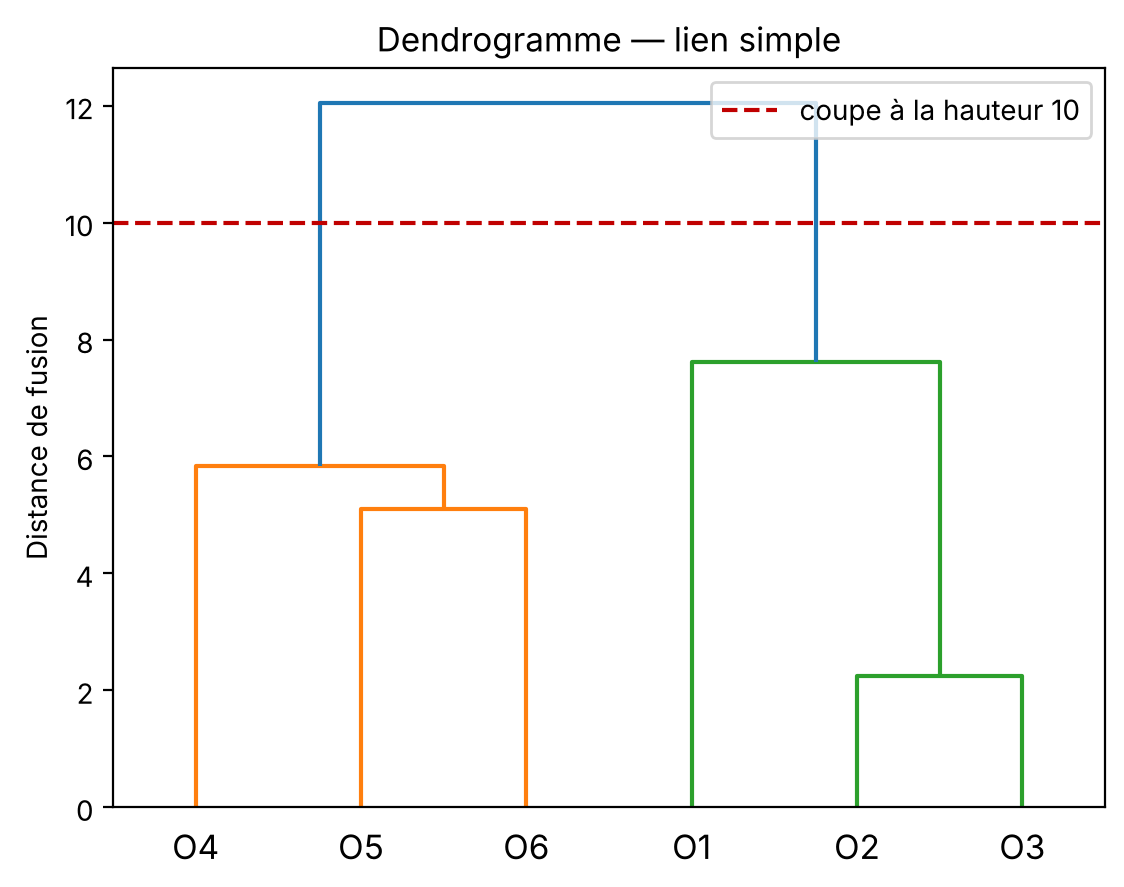

Groupes après la coupe : [2 2 2 1 1 1]


In [7]:
dendrogram(Z, labels=noms, color_threshold=10)
plt.axhline(10, color="#C00000", ls="--", label="coupe à la hauteur 10")
plt.ylabel("Distance de fusion"); plt.title("Dendrogramme — lien simple"); plt.legend(); plt.show()
print("Groupes après la coupe :", fcluster(Z, t=10, criterion="distance"))

## 5. Comparaison des critères d'agrégation

*Le critère d'agrégation change-t-il l'arbre ?*

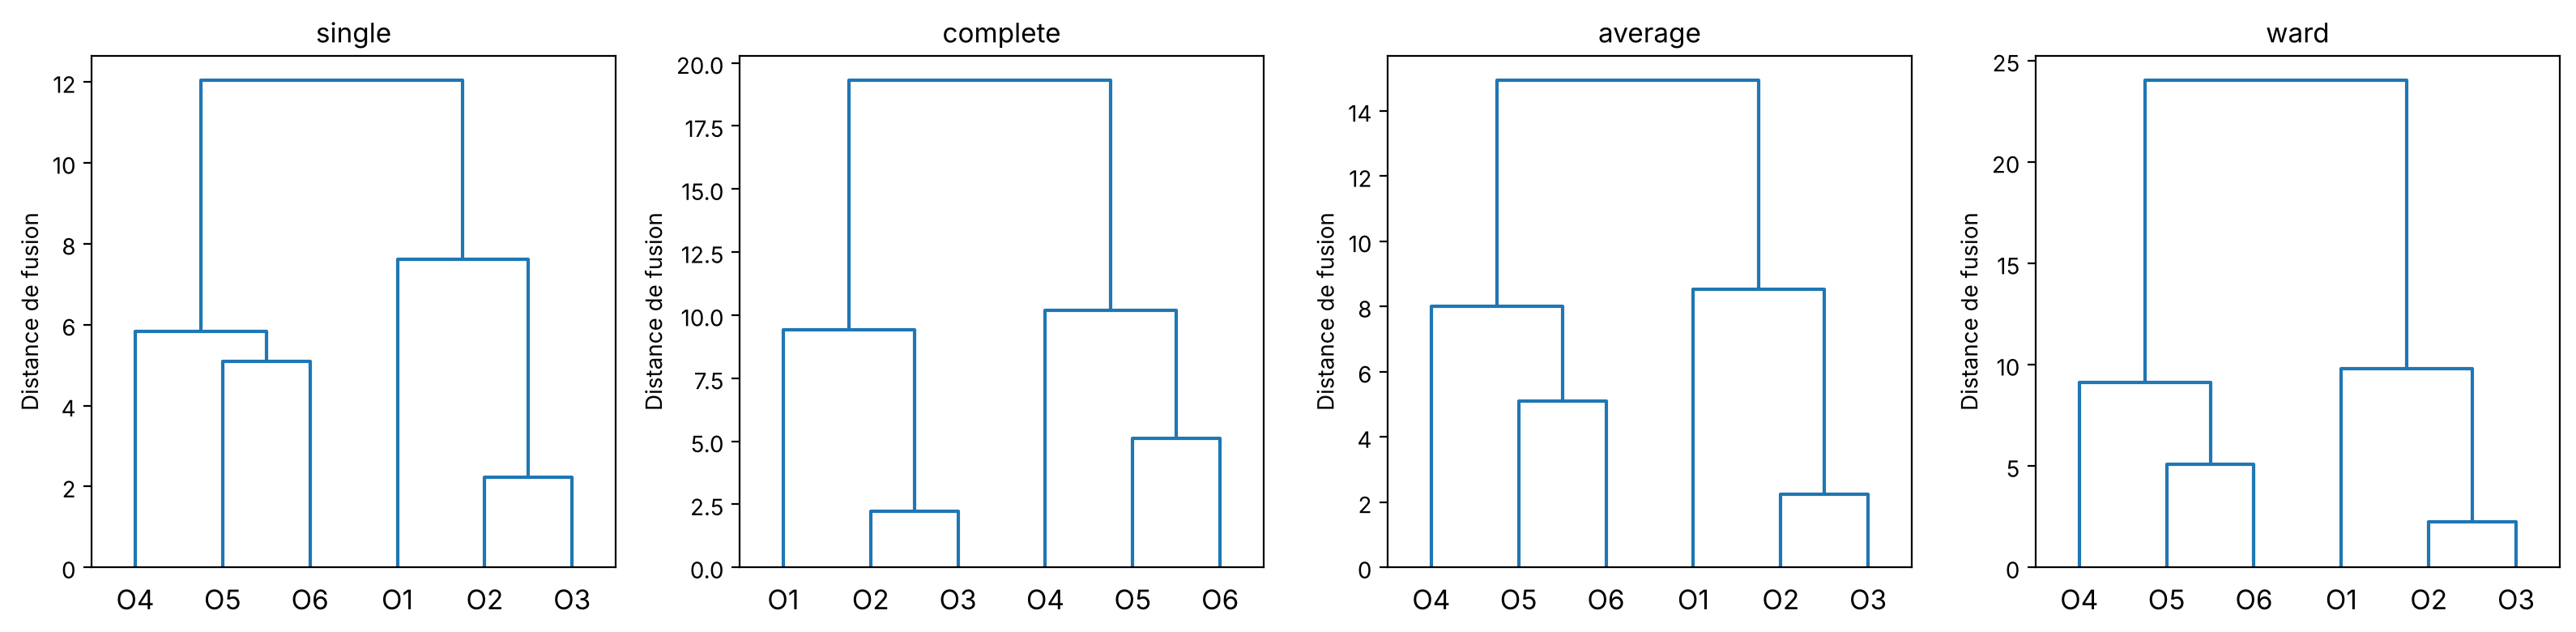

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for critere, ax in zip(["single", "complete", "average", "ward"], axes):
    dendrogram(linkage(X_fleurs, method=critere), labels=noms, ax=ax, color_threshold=0)
    ax.set_title(critere); ax.set_ylabel("Distance de fusion")
plt.tight_layout(); plt.show()

In [9]:
tableau = {c: linkage(X_fleurs, method=c)[:, 2].round(2) for c in ["single", "complete", "average", "ward"]}
pd.DataFrame(tableau, index=[f"fusion {i}" for i in range(1, 6)])

,single,complete,average,ward
fusion 1,2.24,2.24,2.24,2.24
fusion 2,5.10,5.10,5.10,5.10
fusion 3,5.83,9.43,8.01,9.13
fusion 4,7.62,10.20,8.52,9.81
fusion 5,12.04,19.31,14.93,24.03


Les deux premières fusions sont identiques ; les hauteurs suivantes changent selon le critère.

## 6. Cas pratique : la base Iris

*Et sur 150 fleurs ? Le dendrogramme suggère-t-il les trois espèces ?*

On standardise les 4 variables, puis on applique la CAH avec Ward.

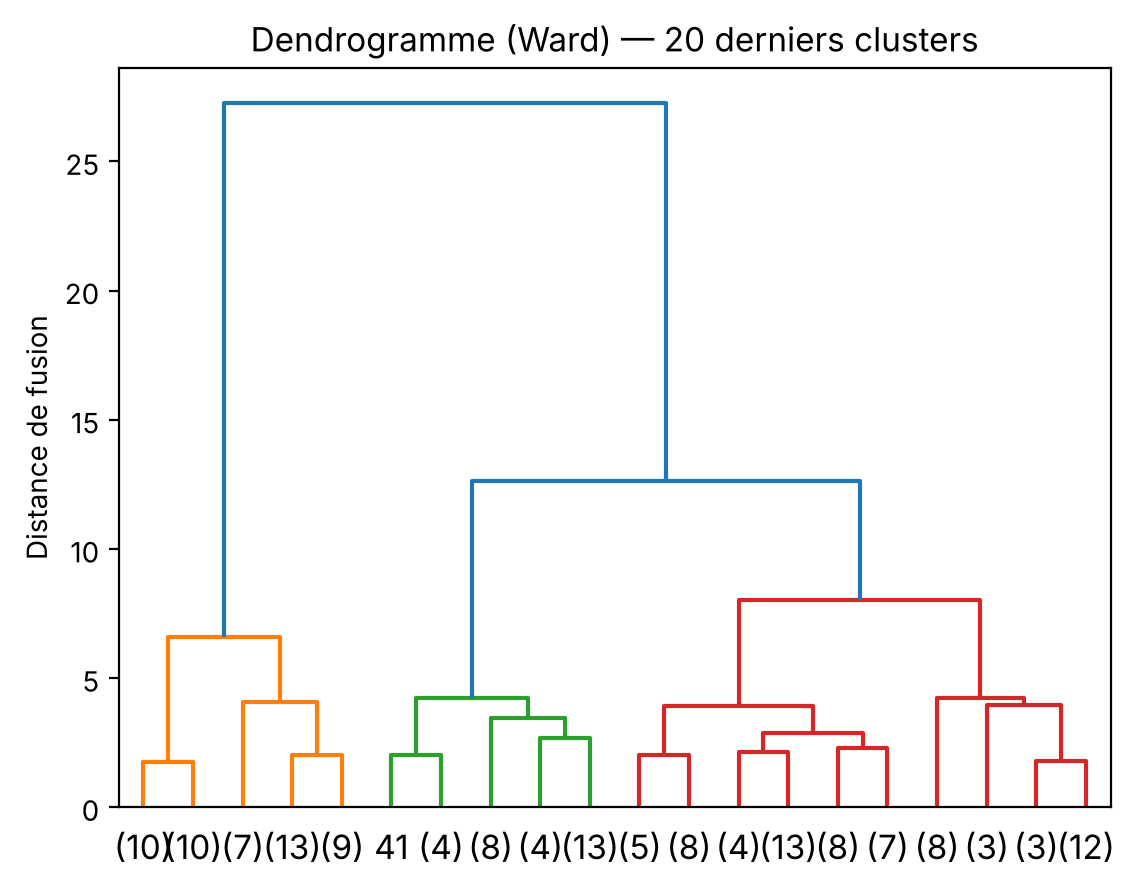

In [10]:
iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)
Z_iris = linkage(X_iris, method="ward")
dendrogram(Z_iris, truncate_mode="lastp", p=20, color_threshold=10)
plt.title("Dendrogramme (Ward) — 20 derniers clusters"); plt.ylabel("Distance de fusion"); plt.show()

Le grand saut suggère de couper en 2 ou 3 groupes. Évaluons les deux avec scikit-learn :

In [11]:
for k in [2, 3, 4]:
    etiquettes = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_iris)
    print(f"K = {k} : silhouette = {silhouette_score(X_iris, etiquettes):.3f}   "
          f"ARI (vs espèces) = {adjusted_rand_score(iris.target, etiquettes):.3f}")

K = 2 : silhouette = 0.577   ARI (vs espèces) = 0.544
K = 3 : silhouette = 0.447   ARI (vs espèces) = 0.615
K = 4 : silhouette = 0.401   ARI (vs espèces) = 0.588


### 6.1 Influence du critère sur Iris (K = 3)

*Tous les critères se valent-ils sur des données réelles ?*

In [12]:
for critere in ["single", "complete", "average", "ward"]:
    etiquettes = AgglomerativeClustering(n_clusters=3, linkage=critere).fit_predict(X_iris)
    tailles = np.bincount(etiquettes)
    print(f"{critere:9s} ARI = {adjusted_rand_score(iris.target, etiquettes):.3f}   tailles = {tailles}")

single    ARI = 0.558   tailles = [100   1  49]
complete  ARI = 0.573   tailles = [77 49 24]
average   ARI = 0.562   tailles = [50 97  3]
ward      ARI = 0.615   tailles = [71 49 30]


Le lien simple crée un « effet de chaîne » (un énorme cluster et de tout petits) ; Ward donne des groupes équilibrés, proches des espèces.

## 7. Exercices

*À vous de jouer ! Les exercices sont classés du plus simple au plus exigeant. Essayez de les faire sans regarder les solutions.*

### Exercice 1 (facile) — Lien complet à la main
Lancez `cah_scratch(6, "complete")`. Quelles fusions et quelles hauteurs obtenez-vous ? Comparez avec `linkage(..., "complete")`.

In [13]:
# À compléter

### Exercice 2 (moyen) — Une fleur aberrante
Ajoutez une 7e fleur $O_7(40, 40)$. Tracez les dendrogrammes simple et Ward. À quelle étape $O_7$ est-elle fusionnée ? Que montre la coupe en 2 groupes ?

In [14]:
# À compléter

### Exercice 3 (défi) — Ward à la main
Écrivez une fonction qui calcule l'augmentation d'inertie de Ward $\Delta = \frac{n_1 n_2}{n_1+n_2}\lVert \mu_1 - \mu_2\rVert^2$ et utilisez-la dans `cah_scratch`. Vérifiez que l'ordre des fusions est le même que `linkage(..., "ward")` (scipy affiche $\sqrt{2\Delta}$).

In [15]:
# À compléter

## 8. Solutions

*Comparez vos réponses avec les propositions ci-dessous ; il existe souvent plusieurs façons correctes de faire.*

<details>
<summary><b>Solution de l'exercice 1</b> (cliquer pour afficher)</summary>

```python
print(cah_scratch(6, "complete", afficher=False))
print(linkage(X_fleurs, "complete")[:, 2].round(2))   # 2.24  5.10  9.43  10.20  19.31
```
</details>

<details>
<summary><b>Solution de l'exercice 2</b> (cliquer pour afficher)</summary>

```python
X7 = np.vstack([X_fleurs, [40, 40]])
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for critere, ax in zip(["single", "ward"], axes):
    Z7 = linkage(X7, critere)
    dendrogram(Z7, labels=noms + ["O7"], ax=ax); ax.set_title(critere)
    print(critere, fcluster(Z7, t=2, criterion="maxclust"))
plt.show()
```
O7 est fusionnée en dernier : une coupe en 2 groupes l'isole seule (comportement d'outlier).
</details>

<details>
<summary><b>Solution de l'exercice 3</b> (cliquer pour afficher)</summary>

```python
def ward(g1, g2):
    m1, m2 = X_fleurs[g1].mean(axis=0), X_fleurs[g2].mean(axis=0)
    n1, n2 = len(g1), len(g2)
    return n1 * n2 / (n1 + n2) * np.sum((m1 - m2) ** 2)

distance_clusters_old = distance_clusters
distance_clusters = lambda g1, g2, critere="ward": ward(g1, g2)
print([(a, b, n, round(np.sqrt(2 * d), 2)) for a, b, n, d in cah_scratch(6, afficher=False)])
distance_clusters = distance_clusters_old
```
</details>

## 9. Conclusion — ce qu'il faut retenir

*Avant de passer à la suite, prenons une minute pour résumer l'essentiel.*

- La CAH fusionne pas à pas les deux clusters les plus proches et **met à jour la matrice des distances**.
- Le **dendrogramme** résume toutes les partitions ; on le **coupe** au niveau d'un grand saut.
- Le critère compte : **lien simple** (effet de chaîne), **complet**, **moyen**, **Ward** (le plus utilisé).
- La CAH est déterministe mais coûteuse (matrice $n \times n$).

➡️ Prochain cours : DBSCAN.